## RNN


In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import string
import unicodedata
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)


### 순환 신경망이란

RNN은 Recurrent Neural Network의 약자로, 순환 신경망이라고 한다. 문장의 단어나 시간별 기온처럼 순서가 있는 데이터를 다루며, 이러한 데이터를 시퀀스라고 한다.
RNN은 데이터를 순서대로 하나씩 읽고, 앞서 읽은 정보를 현재 입력을 처리하는 데 사용한다.

### 은닉 상태와 정보 전달

은닉 상태는 RNN이 지금까지 읽은 입력의 정보를 담아 두는 숫자 벡터다. 앞서 읽은 정보를 다음 입력을 처리하는 데 사용할 수 있게 한다.
은닉 크기가 32라면 이 정보는 32개의 숫자로 표현된다. 이 숫자들은 입력을 읽을 때마다 갱신되며, 어떤 정보를 담을지는 학습을 통해 정해진다.

RNN은 현재 입력과 이전 단계의 은닉 상태를 함께 사용해 새로운 은닉 상태를 만든다. 기본 RNN의 계산식은 다음과 같다.

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b)
$$

$t$는 입력 단계, $x_t$는 현재 입력 벡터이며, $h_{t-1}$과 $h_t$는 이전 단계와 현재 단계의 은닉 상태다.
$W_x$와 $W_h$는 입력과 이전 상태에 적용하는 가중치 행렬이고, $b$는 편향 벡터다. $\tanh$는 각 값을 −1~1 사이로 바꾸는 활성화 함수다.

각 단계에서 같은 가중치와 편향으로 은닉 상태를 갱신하며, 학습할 때는 예측과 정답 사이의 손실을 줄이도록 가중치와 편향을 조정한다.
이 상태를 다음 단계에 전달하는 구조가 반복되기 때문에 ‘순환’이라고 부른다.

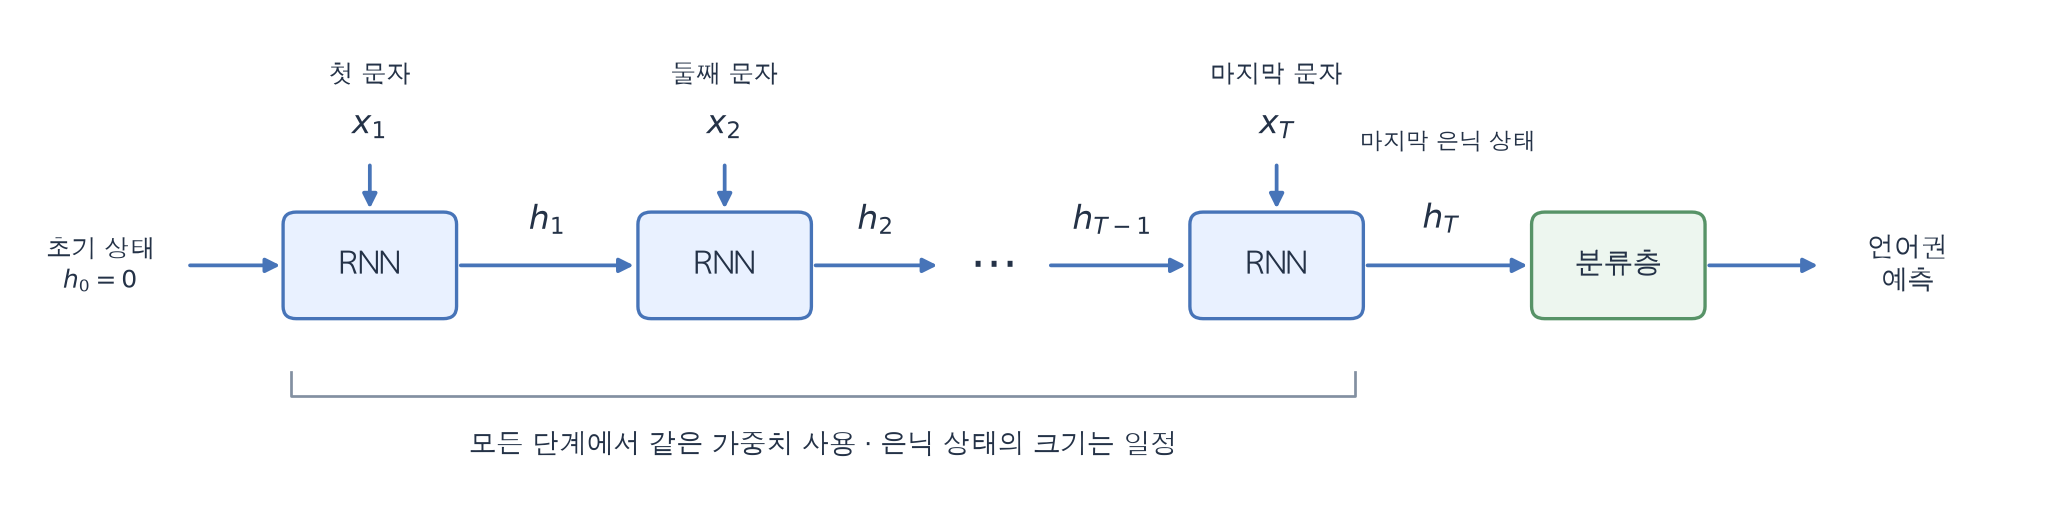

`x₁`, `x₂`는 시퀀스의 첫 번째와 두 번째 입력 벡터다. `h₀`는 첫 입력을 처리하기 전의 초기 상태이며, 여기서는 0 벡터로 둔다. `T`는 시퀀스의 길이다.

1. 첫 입력 `x₁`과 초기 상태 `h₀`를 함께 사용해 첫 입력의 정보를 반영한 `h₁`을 계산한다.
2. 다음 입력 `x₂`와 앞에서 계산한 `h₁`을 함께 사용해 `h₂`를 계산한다. 첫 입력의 정보가 `h₁`을 통해 전달되므로, `h₂`에는 앞서 읽은 정보와 현재 입력의 정보가 함께 반영된다.
3. 같은 방식으로 다음 입력과 직전 상태를 받아 상태를 갱신한다. 마지막에는 `x_T`와 `h_{T-1}`로 `h_T`를 계산한다.
4. 시퀀스 전체를 분류하는 경우, 마지막 상태 `h_T`를 분류층에 넣어 클래스별 점수를 계산한다.

시퀀스가 길어지면 상태를 갱신하는 횟수가 늘어나며, 상태 벡터의 크기는 유지된다.

### RNN의 활용

| 활용 | 순서가 있는 데이터를 사용하는 방법 |
| --- | --- |
| 시퀀스 분류 | 이름의 문자나 리뷰의 단어를 순서대로 읽고, 언어권이나 긍정·부정 같은 라벨을 예측한다 |
| 시계열 예측 | 시간 순서로 기록한 기온·전력 사용량 등의 과거 값을 읽고, 이후의 값을 예측한다 |
| 문자·문장 생성 | 앞서 읽은 문자나 단어를 바탕으로 다음 문자나 단어를 예측한다. 예측한 내용을 다시 입력해 뒤에 이어질 내용을 만든다 |


### 이름 데이터 불러오기

PyTorch 공식 튜토리얼의 18개 언어권 성씨 데이터를 사용한다. 각 파일의 한 줄은 이름 하나이며, 파일 이름이 정답 언어권이다.
이름의 문자 조합과 순서에는 언어권별로 나타나는 패턴이 있어, RNN으로 이러한 패턴을 학습해 언어권을 분류한다.

| 역할 | 열 | 의미 |
| --- | --- | --- |
| 입력 | `name` | 정리한 이름의 철자 |
| 정답 | `language` | 이름에 붙은 언어권 라벨 |

이름은 악센트를 제거하고 영문 대소문자·공백·일부 문장 부호만 남긴다. 정리한 이름과 언어권이 모두 같은 중복 행은 하나만 남긴다.


In [2]:
data_dir = Path("rnn_data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "names.zip"
if not zip_path.exists():
    urlretrieve("https://download.pytorch.org/tutorial/data.zip", zip_path)

rows = []
with zipfile.ZipFile(zip_path) as archive:
    files = sorted(name for name in archive.namelist()
                   if name.startswith("data/names/") and name.endswith(".txt"))
    for filename in files:
        language = Path(filename).stem
        for name in archive.read(filename).decode("utf-8").splitlines():
            rows.append({"raw_name": name, "language": language})
raw = pd.DataFrame(rows)

CHARACTERS = string.ascii_letters + " .,;'"

def normalize_name(name):
    # NFD는 악센트 문자를 기본 문자와 결합 기호로 분해한다.
    decomposed = unicodedata.normalize("NFD", name)
    return "".join(char for char in decomposed
                   if unicodedata.category(char) != "Mn" and char in CHARACTERS).strip()

names = raw.assign(name=raw["raw_name"].map(normalize_name))
names = names.loc[names["name"].str.len() > 0]
names = names.drop_duplicates(["name", "language"]).reset_index(drop=True)
languages = sorted(names["language"].unique())
language_to_id = {language: index for index, language in enumerate(languages)}
names["label"] = names["language"].map(language_to_id)
print("문자 정리:", normalize_name("Ślusàrski"))
print("정리 후 이름·언어권 쌍:", len(names))

display(names[["raw_name", "name", "language"]].head())


문자 정리: Slusarski
정리 후 이름·언어권 쌍: 17994


,raw_name,name,language
0,Khoury,Khoury,Arabic
1,Nahas,Nahas,Arabic
2,Daher,Daher,Arabic
3,Gerges,Gerges,Arabic
4,Nazari,Nazari,Arabic


### 학습·검증·테스트 분리

고유한 이름 철자를 무작위로 섞어 학습·검증·테스트에 약 70%·15%·15%로 배정한다.
같은 철자는 언어권 라벨이 달라도 한 구간에만 넣어, 학습과 평가 데이터에 같은 이름이 섞이지 않게 한다.


In [3]:
unique_names = names["name"].unique()
rng = np.random.default_rng(SEED)

# 고정한 시드로 고유한 철자의 순서를 섞는다.
shuffled = rng.permutation(unique_names)
train_end, val_end = int(len(shuffled) * 0.7), int(len(shuffled) * 0.85)
name_groups = {"train": shuffled[:train_end], "validation": shuffled[train_end:val_end],
               "test": shuffled[val_end:]}

# 같은 철자에 속한 행을 모두 같은 구간으로 가져온다.
frames = {split: names.loc[names["name"].isin(group)].reset_index(drop=True)
          for split, group in name_groups.items()}
display(pd.DataFrame({split: frame["language"].value_counts()
                      for split, frame in frames.items()}).reindex(languages))


,train,validation,test
language,,,
Arabic,71,18,19
Chinese,175,37,34
Czech,364,65,73
Dutch,200,44,42
English,2556,563,549
French,193,39,41
German,499,101,90
Greek,127,35,31
Irish,149,40,37


### 문자를 원핫 벡터로 표현하기

RNN은 각 단계에서 숫자 벡터를 입력받으므로, 이름의 각 문자를 벡터로 바꿔야 한다.
원핫 벡터를 사용하면 문자 번호의 크기에 따른 대소 관계 없이 각 문자를 구별할 수 있다.

이름의 문자들을 원핫 벡터로 바꾸고 원래 순서대로 쌓는다. RNN은 이 벡터를 한 문자씩 읽으며 은닉 상태를 갱신한다.


In [4]:
char_to_id = {char: index for index, char in enumerate(CHARACTERS)}
N_CHARACTERS = len(CHARACTERS)
N_CLASSES = len(languages)

def encode_name(name):
    indices = torch.tensor([char_to_id[char] for char in name], dtype=torch.long)

    # one_hot: (문자 수,) 정수 → (문자 수, 문자 종류 수). RNN 입력은 float32다.
    return nn.functional.one_hot(indices, num_classes=N_CHARACTERS).float()

example_name = "Kim"
encoded = encode_name(example_name)
display(pd.DataFrame({"character": list(example_name),
                      "index": [char_to_id[char] for char in example_name]}))
print("원핫 입력 모양:", encoded.shape)

# 행은 이름의 각 문자, 열은 입력으로 사용할 수 있는 문자다.
one_hot_df = pd.DataFrame(encoded.numpy(), index=list(example_name), columns=list(CHARACTERS))
with pd.option_context("display.max_columns", None):
    display(one_hot_df)


,character,index
0,K,36
1,i,8
2,m,12


원핫 입력 모양: torch.Size([3, 57])


,a,b,c,d,e,f,g,h,i,j,k,l,m,n,o,p,q,r,s,t,u,v,w,x,y,z,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,T,U,V,W,X,Y,Z,,.,",",;,'
K,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
i,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
m,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 입력과 정답 준비

이름의 원핫 벡터와 정답 언어권 번호를 한 쌍으로 묶어, 이름별로 꺼낼 수 있게 준비한다.


In [5]:
class NamesDataset(Dataset):
    def __init__(self, frame):
        self.inputs = [encode_name(name) for name in frame["name"]]
        self.labels = frame["label"].to_numpy()

    def __len__(self):
        return len(self.labels)

    # dataset[index]로 접근할 때 해당 이름의 입력과 정답 한 쌍을 꺼낸다.
    def __getitem__(self, index):
        # (이름 길이, 문자 종류 수), 정수 정답
        return self.inputs[index], int(self.labels[index])

datasets = {split: NamesDataset(frame) for split, frame in frames.items()}


### 길이가 다른 이름을 배치로 묶기

여러 이름을 한 배치로 묶어 처리한다. 이름마다 길이가 달라 짧은 이름 뒤에 0 벡터를 붙인다.
이처럼 길이를 맞추는 처리를 패딩이라고 한다. 각 배치에서 가장 긴 이름에 맞춰 패딩하므로, 배치마다 입력의 최대 길이는 달라질 수 있다.
각 이름의 실제 길이도 함께 보관한다.


In [6]:
def collate_names(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)

    # 입력 모양: (배치, 배치 안의 최대 길이, 문자 종류 수).
    inputs = pad_sequence(
        sequences,
        # 배치 축을 맨 앞에 둔다.
        batch_first=True,
        # 짧은 이름의 뒤쪽을 0 벡터로 채운다.
        padding_value=0.0,
    )
    return inputs, lengths, torch.tensor(labels, dtype=torch.long)

BATCH_SIZE = 64
def make_train_loader():
    return DataLoader(
        datasets["train"],
        batch_size=BATCH_SIZE,
        # 이름 샘플의 순서를 섞는다.
        shuffle=True,
        # 샘플 목록을 패딩된 한 배치로 변환한다.
        collate_fn=collate_names,
        # 두 모델의 학습에서 같은 순서로 배치를 만든다.
        generator=torch.Generator().manual_seed(SEED),
    )

val_loader = DataLoader(datasets["validation"], batch_size=BATCH_SIZE, collate_fn=collate_names)
test_loader = DataLoader(datasets["test"], batch_size=BATCH_SIZE, collate_fn=collate_names)
inputs, lengths, labels = next(iter(make_train_loader()))
print("입력·길이·정답 모양:", inputs.shape, lengths.shape, labels.shape)


입력·길이·정답 모양: torch.Size([64, 13, 57]) torch.Size([64]) torch.Size([64])


### RNN 모델 구성

문자를 순서대로 읽는 RNN 층과 언어권별 점수를 계산하는 선형층을 연결한다.
한 번 호출하면 배치 안의 입력을 첫 문자부터 패딩을 포함한 마지막 위치까지 순서대로 처리한다. 문자 위치를 따라 은닉 상태를 갱신하는 반복은 RNN 내부에서 이루어진다.
출력에는 각 입력 위치의 은닉 상태가 담긴다.
이름의 실제 길이를 기준으로 마지막 문자의 은닉 상태를 골라 선형층에 넣는다. 선형층이 계산한 언어권별 점수를 로짓이라고 한다.


In [7]:
class NameRNN(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(
            # 문자 하나를 나타내는 벡터의 크기.
            input_size=N_CHARACTERS,
            # 은닉 상태 벡터의 크기.
            hidden_size=hidden_size,
            # 입력과 출력에서 배치 축을 맨 앞에 둔다.
            batch_first=True,
        )
        self.head = nn.Linear(hidden_size, N_CLASSES)

    def forward(self, inputs, lengths):
        # outputs에는 각 입력 위치의 은닉 상태가 담긴다. 패딩 위치의 상태도 포함된다.
        # 모양: (배치, 최대 길이, 은닉 크기).
        outputs, _ = self.rnn(inputs)

        # 배치 안의 이름 번호.
        batch_indices = torch.arange(inputs.size(0))

        # 실제 길이를 기준으로 이름마다 마지막 문자의 은닉 상태를 고른다.
        last_outputs = outputs[batch_indices, lengths - 1]

        # 로짓: (배치, 언어권 수)
        return self.head(last_outputs)


### 분류 손실

교차 엔트로피는 정답 클래스에 높은 확률을 줄수록 작아지는 분류 손실이다.
모델이 출력한 로짓과 정답 언어권을 이용해 손실을 계산한다.

### 정확도와 macro F1

정확도와 함께 macro F1을 사용한다. macro F1은 18개 언어권 각각의 F1을 구한 뒤 같은 비중으로 평균 낸 값이다.
언어권별 표본 수가 달라도 각 언어권의 분류 성능을 동일한 비중으로 평가한다.


In [9]:
# 로짓 (배치, 언어권 수), long 정답 (배치,) → 평균 손실 하나.
criterion = nn.CrossEntropyLoss()

def classification_scores(truth, predicted):
    return {
        "accuracy": accuracy_score(truth, predicted),
        "macro_F1": f1_score(
            truth,
            predicted,
            labels=list(range(N_CLASSES)),
            # 언어권별 F1을 같은 비중으로 평균 낸다.
            average="macro",
            # 분모가 0인 지표는 0으로 둔다.
            zero_division=0,
        ),
    }

@torch.no_grad()
def evaluate_names(model, loader):
    model.eval()
    total_loss, count = 0.0, 0
    truth, predicted = [], []
    for inputs, lengths, labels in loader:
        logits = model(inputs, lengths)
        total_loss += criterion(logits, labels).item() * len(labels)
        count += len(labels)
        truth.extend(labels.cpu().tolist())

        # 가장 큰 로짓의 클래스 번호.
        predicted.extend(logits.argmax(dim=1).cpu().tolist())
    return {"loss": total_loss / count, **classification_scores(truth, predicted)}, np.array(predicted)


### 모델 학습

마지막 예측에서 계산한 손실을 바탕으로, 문자 순서를 거슬러 은닉 상태 계산을 따라 기울기를 구한다. 이 기울기로 모든 문자 위치에서 공유하는 가중치를 갱신한다.
학습을 안정적으로 진행하기 위해 기울기 크기에 상한을 둔다.

Adam으로 20에포크 학습한다. 매 에포크의 학습·검증 손실과 검증 지표를 기록하고 마지막 에포크의 모델을 평가한다.


In [10]:
def fit_names(model, epochs=20):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loader = make_train_loader()
    history = []
    for epoch in range(epochs):
        model.train()
        total_loss, count = 0.0, 0
        for inputs, lengths, labels in loader:
            loss = criterion(model(inputs, lengths), labels)
            
            optimizer.zero_grad()
            loss.backward()

            # 전체 파라미터 기울기를 모은 벡터의 길이를 최대 1로 제한한다.
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(labels)
            count += len(labels)
        scores, _ = evaluate_names(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": total_loss / count,
                        "val_loss": scores["loss"], "val_accuracy": scores["accuracy"],
                        "val_macro_F1": scores["macro_F1"]})
        print(f"epoch={epoch+1}, val_loss={scores['loss']:.3f}, macro_F1={scores['macro_F1']:.3f}")
    model.eval()
    return pd.DataFrame(history)

torch.manual_seed(SEED)
base_model = NameRNN(hidden_size=32)
base_history = fit_names(base_model)
base_scores, _ = evaluate_names(base_model, val_loader)
display(pd.DataFrame([{
    "model": "RNN 32",
    "accuracy": base_scores["accuracy"],
    "macro_F1": base_scores["macro_F1"],
}]))


epoch=1, val_loss=1.436, macro_F1=0.073
epoch=2, val_loss=1.212, macro_F1=0.111
epoch=3, val_loss=1.118, macro_F1=0.125
epoch=4, val_loss=1.060, macro_F1=0.148
epoch=5, val_loss=1.006, macro_F1=0.166
epoch=6, val_loss=0.975, macro_F1=0.190
epoch=7, val_loss=0.936, macro_F1=0.192
epoch=8, val_loss=0.919, macro_F1=0.209
epoch=9, val_loss=0.895, macro_F1=0.220
epoch=10, val_loss=0.882, macro_F1=0.225
epoch=11, val_loss=0.870, macro_F1=0.237
epoch=12, val_loss=0.859, macro_F1=0.251
epoch=13, val_loss=0.847, macro_F1=0.262
epoch=14, val_loss=0.836, macro_F1=0.264
epoch=15, val_loss=0.835, macro_F1=0.264
epoch=16, val_loss=0.822, macro_F1=0.269
epoch=17, val_loss=0.817, macro_F1=0.276
epoch=18, val_loss=0.805, macro_F1=0.287
epoch=19, val_loss=0.807, macro_F1=0.289
epoch=20, val_loss=0.800, macro_F1=0.284


,model,accuracy,macro_F1
0,RNN 32,0.76099,0.284058


### 학습·검증 손실 해석

가로축은 에포크, 세로축은 교차 엔트로피 손실이다.
학습 손실이 줄어드는 동안 검증 손실이 커지면 학습 이름에 과도하게 맞추는 과적합을 의심할 수 있다.
두 곡선의 변화를 비교하고 학습이 진행되면서 검증 손실도 함께 줄어드는지 설명한다.


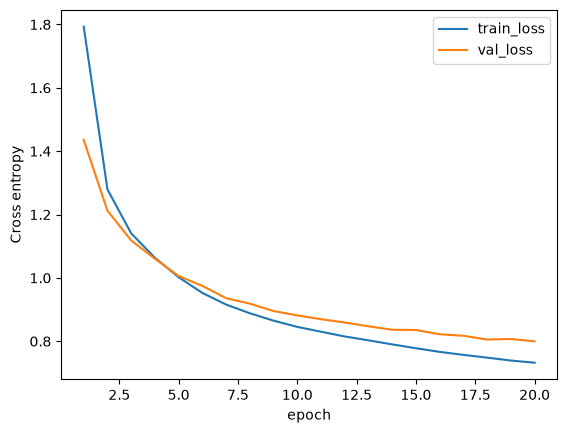

In [11]:
base_history.plot(x="epoch", y=["train_loss", "val_loss"], ylabel="Cross entropy")
plt.show()


## RNN 모델 비교와 선택

### 은닉 상태 크기 바꾸기

은닉 상태 크기는 각 문자 위치에서 정보를 담는 벡터의 차원 수다. 크기를 늘리면 학습할 파라미터 수도 늘어난다.
데이터 분할·배치 크기·학습률·학습 횟수 20에포크를 유지하고 은닉 상태 크기만 64로 바꾸어 새 모델을 학습한다.

- 두 모델의 검증 정확도와 macro F1은 어떻게 달라졌는가?
- 파라미터 수가 늘어난 정도와 검증 지표의 변화를 함께 설명한다. 성능 차이가 작거나 나빠진 결과도 해석한다.


In [12]:
torch.manual_seed(SEED)
wide_model = NameRNN(hidden_size=64)
wide_history = fit_names(wide_model)
models = {32: base_model, 64: wide_model}
rows = []
for width, candidate in models.items():
    scores, _ = evaluate_names(candidate, val_loader)
    rows.append({"hidden_size": width, "val_accuracy": scores["accuracy"],
                 "val_macro_F1": scores["macro_F1"],
                 "parameters": sum(parameter.numel() for parameter in candidate.parameters())})
comparison = pd.DataFrame(rows)
display(comparison)


epoch=1, val_loss=1.371, macro_F1=0.078
epoch=2, val_loss=1.168, macro_F1=0.116
epoch=3, val_loss=1.049, macro_F1=0.161
epoch=4, val_loss=0.983, macro_F1=0.174
epoch=5, val_loss=0.919, macro_F1=0.201
epoch=6, val_loss=0.890, macro_F1=0.244
epoch=7, val_loss=0.867, macro_F1=0.250
epoch=8, val_loss=0.854, macro_F1=0.263
epoch=9, val_loss=0.832, macro_F1=0.285
epoch=10, val_loss=0.820, macro_F1=0.291
epoch=11, val_loss=0.799, macro_F1=0.298
epoch=12, val_loss=0.796, macro_F1=0.304
epoch=13, val_loss=0.787, macro_F1=0.307
epoch=14, val_loss=0.775, macro_F1=0.312
epoch=15, val_loss=0.770, macro_F1=0.317
epoch=16, val_loss=0.760, macro_F1=0.319
epoch=17, val_loss=0.765, macro_F1=0.338
epoch=18, val_loss=0.755, macro_F1=0.337
epoch=19, val_loss=0.769, macro_F1=0.332
epoch=20, val_loss=0.759, macro_F1=0.343


,hidden_size,val_accuracy,val_macro_F1,parameters
0,32,0.76099,0.284058,3506
1,64,0.77355,0.343043,9042


### 검증 결과로 모델 선택

두 RNN 중 검증 macro F1이 큰 모델을 선택한다.
언어권별 표본 수의 차이를 고려해 각 언어권에 같은 비중을 두는 기준이다.


In [13]:
selected_width = int(comparison.loc[comparison["val_macro_F1"].idxmax(), "hidden_size"])
selected_model = models[selected_width]
print("선택한 은닉 상태 크기:", selected_width)


선택한 은닉 상태 크기: 64


### 언어권별 오류 사례

오류가 있는 언어권마다 최대 두 개의 이름을 표시한다.
검증 이름의 철자와 오류를 함께 살펴보고, 표본 수와 비슷한 철자 패턴이 결과에 미쳤을 가능성을 설명한다.


In [14]:
_, val_predictions = evaluate_names(selected_model, val_loader)
truth = frames["validation"]["label"].to_numpy()
examples = frames["validation"][["name", "language"]].copy()
examples["prediction"] = [languages[index] for index in val_predictions]
errors = examples.loc[truth != val_predictions]

error_examples = errors.groupby("language", sort=True).head(2)
display(error_examples.reset_index(drop=True))


,name,language,prediction
0,Gerges,Arabic,English
1,Maalouf,Arabic,Russian
2,AuYong,Chinese,English
3,Bian,Chinese,English
4,Buchta,Czech,Russian
5,Cernohous,Czech,English
6,Amersvoort,Dutch,Russian
7,Amstel,Dutch,English
8,Abraham,English,Russian
9,Alexander,English,Russian


### 언어권별 혼동 행렬

혼동 행렬의 행은 실제 언어권, 열은 예측 언어권이다. 각 행의 합을 1로 맞추어 언어권별 예측 비율을 표시한다.
대각선은 맞힌 비율이고, 나머지는 다른 언어권으로 분류한 비율이다.
검증 이름이 어떤 언어권으로 자주 혼동되는지 확인한다.


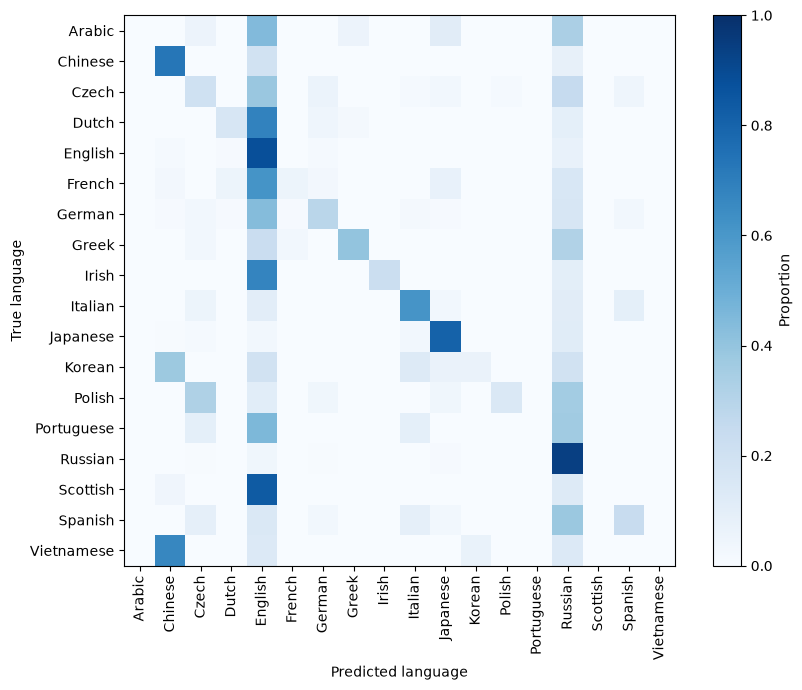

: 

In [ ]:
# normalize="true": 실제 클래스별 행을 정규화한다. 결과: (언어권 수, 언어권 수).
matrix = confusion_matrix(truth, val_predictions, labels=list(range(N_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(N_CLASSES), languages, rotation=90)
ax.set_yticks(range(N_CLASSES), languages)
ax.set_xlabel("Predicted language")
ax.set_ylabel("True language")
fig.colorbar(plot, ax=ax, label="Proportion")
plt.tight_layout()
plt.show()


### 이름 한 개 분류하기

이름을 학습 데이터와 같은 방식으로 정리하고 문자 순서대로 모델에 넣는다.
언어권별 로짓을 합이 1인 확률로 바꾸고, 확률이 가장 높은 세 언어권을 확인한다.


In [ ]:
@torch.no_grad()
def predict_name(name):
    cleaned = normalize_name(name)
    if not cleaned:
        raise ValueError("영문자로 표현할 수 있는 이름을 입력하세요.")
    selected_model.eval()
    inputs = encode_name(cleaned).unsqueeze(0)
    lengths = torch.tensor([len(cleaned)])
    probabilities = selected_model(inputs, lengths).softmax(dim=1)[0].cpu()

    # topk(3): 가장 큰 값 3개와 그 위치를 반환한다.
    values, indices = probabilities.topk(3)
    return pd.DataFrame({"name": cleaned, "language": [languages[i] for i in indices.tolist()],
                         "probability": values.numpy()})

display(predict_name("Kim"))


### 최종 테스트

검증 결과로 선택을 마친 RNN을 테스트 데이터에서 평가한다.
테스트 점수는 이후 설정을 고르는 데 사용하지 않는다.


In [ ]:
test_scores, _ = evaluate_names(selected_model, test_loader)
display(pd.DataFrame([{
    "model": f"RNN {selected_width}",
    "accuracy": test_scores["accuracy"],
    "macro_F1": test_scores["macro_F1"],
}]))
